<table border=0 width="100%"><tr><td><font size=5><B>week04-homework-api-data</B></font></td></tr></table>

# 第四周作业：选择1家上市公司并结合tushare获取数据进行分析
- 自由选择1家感兴趣的上市公司；
- 针对你选择的公司，提出一个你感兴趣的问题；
- 应用tushare获取与该公司相关的数据（不限于股市价格数据、财务等数据，国家宏观等数据均可使用）；
- 尝试应用你采集的数据做数据分析，回答你提出的问题。


提交作业：
- 在线提交：http://swufe.fanya.chaoxing.com/portal
- 截止日期：2026年10月16日晚上8点
- 提交**这个jupyter文档**，命名为“week04-homework-api-data_学号_姓名.ipynb”，学号姓名替换为自己的学号和姓名
- jupyter文档你要完成的包括四部分：公司名称与基本简介、研究问题题目及其内涵介绍、数据采集、数据分析与问题解答
- 为了批改方便，我这里将tushare token直接放到代码中

# 第一部分：公司名称与基本简介

1. 公司名称与基本简介
研究目的：五粮液（股票代码：000858.SZ）
宜宾五粮液股份有限公司在深圳证券交易所上市，是国内浓香型高端白酒龙头企业。主营业务为五粮液系列白酒产品的生产、销售，属于消费板块核心标的。
本次作业选取2025年08月20日至2026年10月31日的股票日线交易数据，利用Tushare接口获取行情数据，开展时间序列分析。


# 第二部分：研究问题题目及其内涵介绍

2. 研究问题题目及其内涵介绍
研究问题：五粮液（000858.SZ）在2025-08-20至2026-10-31时间段内，股价走势具备什么特征？
问题内涵：
我们通过股票每日收盘价时序图直观观察股价的涨跌趋势；借助均值、标准差、最高价、最低价等统计指标，量化该时间段内股价的中枢水平与波动风险，以此回答研究问题。


# 第三部分：数据采集

In [14]:
import tushare as ts
import pandas as pd
import matplotlib.pyplot as plt
# 为了批改方便，我这里将tushare token直接放到代码中
token = "5c426f5af978fd42fe0f81fe7e60c02ada33d6c79347b61ccb44f521"
ts.set_token(token=token)
pro = ts.pro_api()



ts_code = "000858.SZ"
start_date = "20250820"
end_date = "20261031"


df = pro.daily(ts_code=ts_code, start_date=start_date, end_date=end_date)
df = df.sort_values("trade_date").reset_index(drop=True)
df["trade_date"] = pd.to_datetime(df["trade_date"])


print("数据集预览：")
display(df.head())
print("\n数据集信息：")
display(df.info())


数据集预览：


,ts_code,trade_date,open,high,low,close,pre_close,change,pct_chg,vol,amount
0,000858.SZ,2025-08-20,124.42,126.50,123.35,125.78,124.41,1.37,1.1012,404310.44,5083056.591
1,000858.SZ,2025-08-21,125.80,126.13,124.86,125.45,125.78,-0.33,-0.2624,231894.77,2908492.491
2,000858.SZ,2025-08-22,125.45,125.82,124.95,125.79,125.45,0.34,0.2710,204849.97,2567683.361
3,000858.SZ,2025-08-25,126.18,130.09,126.18,129.93,125.79,4.14,3.2912,479800.03,6165955.081
4,000858.SZ,2025-08-26,129.93,131.85,128.65,129.74,129.93,-0.19,-0.1462,349794.45,4552425.053



数据集信息：
<class 'pandas.DataFrame'>
RangeIndex: 279 entries, 0 to 278
Data columns (total 11 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   ts_code     279 non-null    str           
 1   trade_date  279 non-null    datetime64[us]
 2   open        279 non-null    float64       
 3   high        279 non-null    float64       
 4   low         279 non-null    float64       
 5   close       279 non-null    float64       
 6   pre_close   279 non-null    float64       
 7   change      279 non-null    float64       
 8   pct_chg     279 non-null    float64       
 9   vol         279 non-null    float64       
 10  amount      279 non-null    float64       
dtypes: datetime64[us](1), float64(9), str(1)
memory usage: 26.6 KB


None

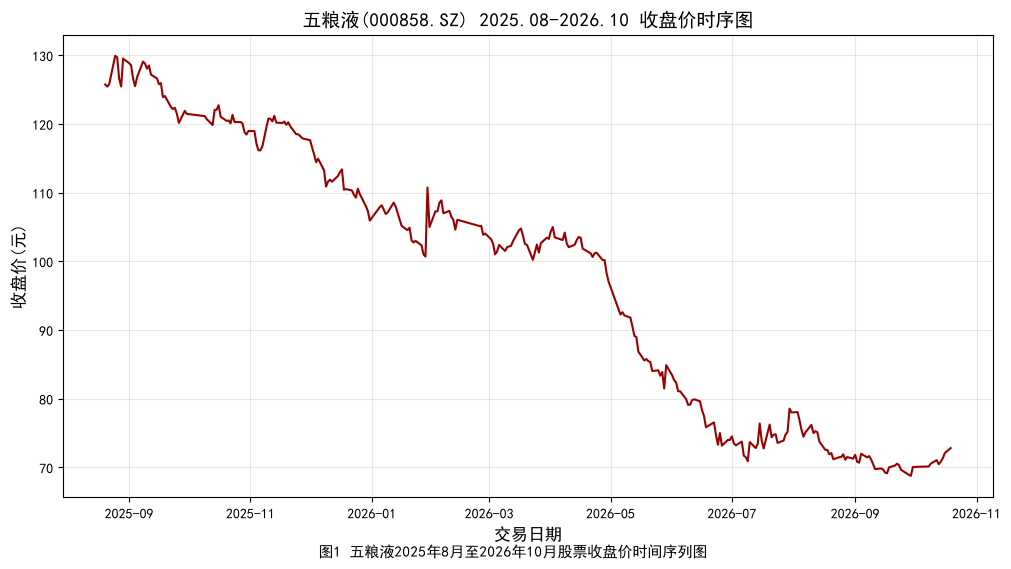

In [15]:


plt.rcParams['font.sans-serif'] = ['SimHei']  
plt.rcParams['axes.unicode_minus'] = False    

plt.figure(figsize=(12,6))
plt.plot(df["trade_date"], df["close"], color="#990000", linewidth=1.5)
plt.title("五粮液(000858.SZ) 2025.08-2026.10 收盘价时序图", fontsize=14)
plt.xlabel("交易日期", fontsize=12)
plt.ylabel("收盘价(元)", fontsize=12)
plt.grid(alpha=0.3)


plt.figtext(0.5, 0.01, "图1 五粮液2025年8月至2026年10月股票收盘价时间序列图", ha="center", fontsize=11)

plt.show()



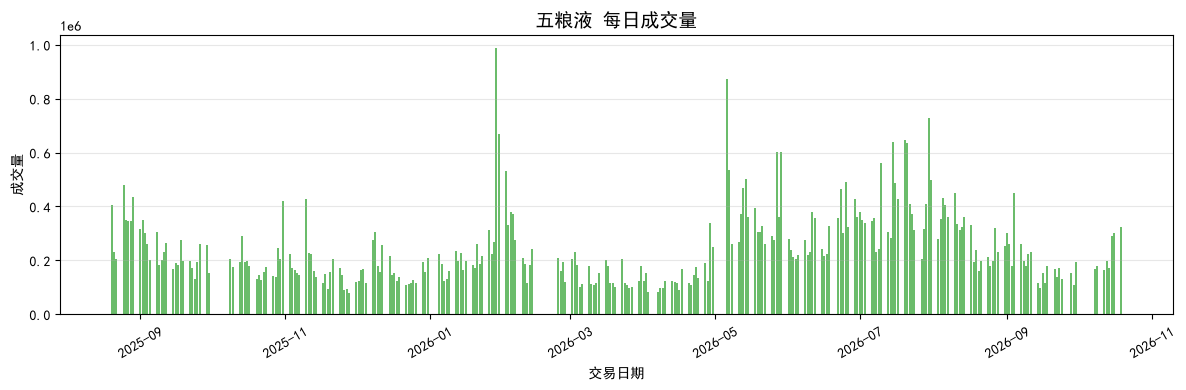

In [16]:
plt.figure(figsize=(12,4))
plt.bar(df['trade_date'], df['vol'], color="#2ca02c", alpha=0.7)
plt.title("五粮液 每日成交量", fontsize=14)
plt.xlabel("交易日期")
plt.ylabel("成交量")
plt.xticks(rotation=30)
plt.grid(alpha=0.3, axis="y")
plt.tight_layout()
plt.show()


In [17]:
close_mean = df["close"].mean()
close_std = df["close"].std()
max_price = df["close"].max()
min_price = df["close"].min()

print("=====收盘价统计结果====")
print(f"平均收盘价: {close_mean:.2f} 元")
print(f"收盘价标准差: {close_std:.2f}")
print(f"区间最高收盘价: {max_price:.2f} 元")
print(f"区间最低收盘价: {min_price:.2f} 元")

ret_mean = df["pct_change"].mean()
ret_std = df["pct_change"].std()

plt.figure(figsize=(10,5))
plt.hist(df["pct_change"].dropna(), bins=30, color="#c82423", alpha=0.7)

# 均值竖线
plt.axvline(ret_mean, color="black", linestyle="--", lw=2, label=f'均值={ret_mean:.4f}')

plt.title("五粮液每日收益率分布直方图", fontsize=14)
plt.xlabel("单日收益率", fontsize=12)
plt.ylabel("频次", fontsize=12)
plt.grid(alpha=0.3)

# 文本标注
text_info = f'收益率均值 = {ret_mean:.4f}\n收益率标准差 = {ret_std:.4f}'
plt.text(0.05, plt.ylim()[1]*0.8, text_info, bbox=dict(facecolor='white', alpha=0.8), fontsize=11)

plt.legend()
plt.tight_layout()
plt.show()


=====收盘价统计结果====
平均收盘价: 97.75 元
收盘价标准差: 19.63
区间最高收盘价: 129.93 元
区间最低收盘价: 68.77 元


KeyError: 'pct_change'

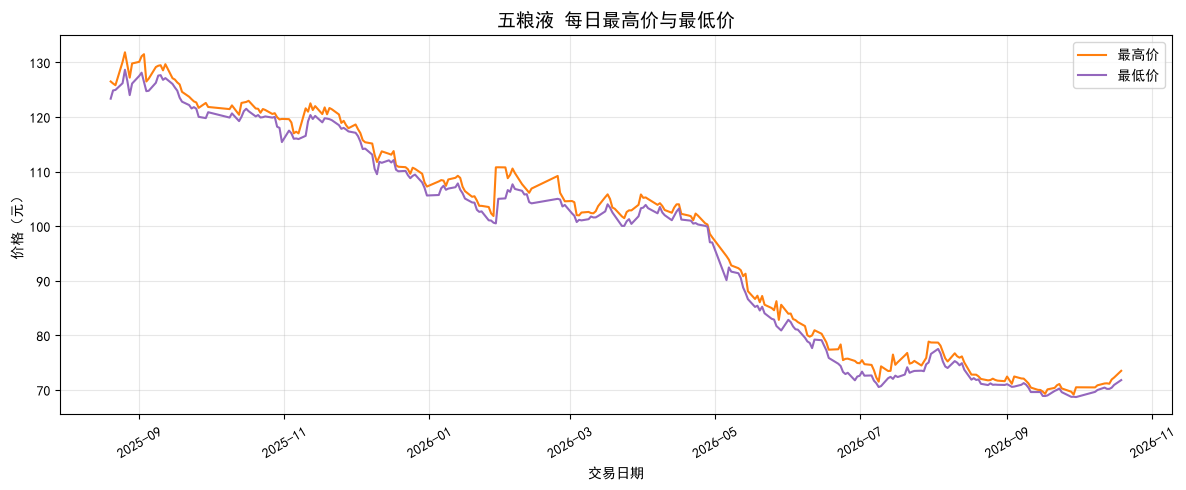

In [18]:
plt.figure(figsize=(12,5))
plt.plot(df['trade_date'], df['high'], label="最高价", color="#ff7f0e")
plt.plot(df['trade_date'], df['low'], label="最低价", color="#9467bd")
plt.title("五粮液 每日最高价与最低价", fontsize=14)
plt.xlabel("交易日期")
plt.ylabel("价格（元）")
plt.xticks(rotation=30)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [19]:
plt.figure(figsize=(12,4))
plt.plot(df['trade_date'], df['pct_change'], color="#d62728", linewidth=1)
plt.axhline(y=0, color="black", linestyle="--", alpha=0.6)
plt.title("五粮液 日收益率时序图", fontsize=14)
plt.xlabel("交易日期")
plt.ylabel("日收益率")
plt.xticks(rotation=30)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


KeyError: 'pct_change'

<Figure size 1200x400 with 0 Axes>

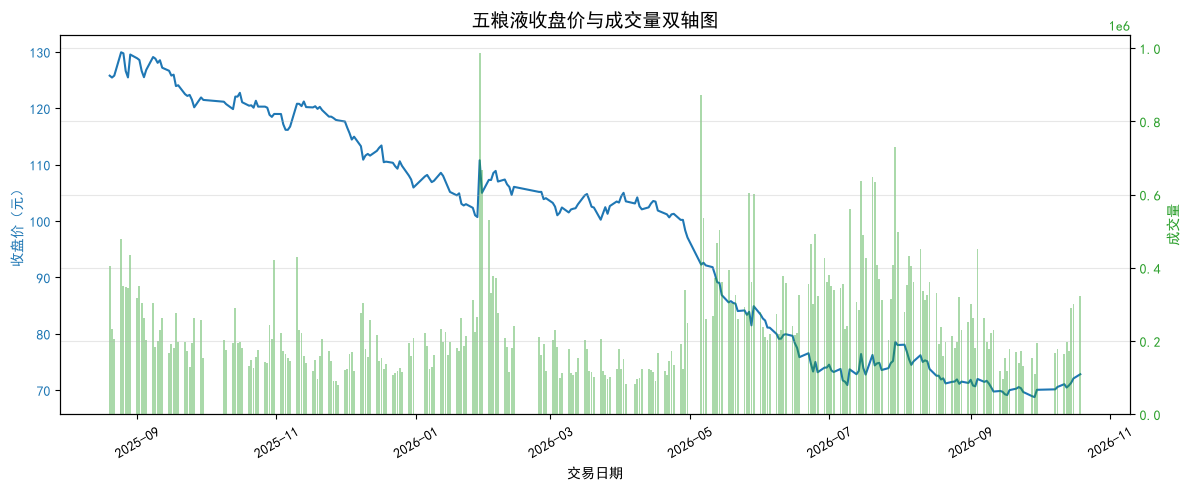

In [20]:
fig, ax1 = plt.subplots(figsize=(12,5))

color1 = "#1f77b4"
ax1.set_xlabel("交易日期")
ax1.set_ylabel("收盘价（元）", color=color1)
ax1.plot(df['trade_date'], df['close'], color=color1)
ax1.tick_params(axis='y', labelcolor=color1)
plt.xticks(rotation=30)

ax2 = ax1.twinx()
color2 = "#2ca02c"
ax2.set_ylabel("成交量", color=color2)
ax2.bar(df['trade_date'], df['vol'], alpha=0.4, color=color2)
ax2.tick_params(axis='y', labelcolor=color2)

plt.title("五粮液收盘价与成交量双轴图", fontsize=14)
plt.grid(alpha=0.3)
fig.tight_layout()
plt.show()


# 第四部分：数据分析过程

  4．数据分析与问题解答
数据分析内容
1. 时序图分析：从收盘价时间序列图，可以直观看到五粮液股价在选定区间内随时间变化的整体趋势，能够观察到阶段性上涨、回调的时间节点。
2. 统计指标解读
    - 收盘价均值：代表这段时间股价的平均价格中枢；
    - 标准差：衡量股价波动大小，标准差越大，代表股价震荡越剧烈；
    - 最高价、最低价：反映该时间段股价波动的上下边界。
3. 涨跌幅直方图：展示每日股价涨跌幅的分布情况，可以看出大部分交易日涨跌幅集中在某个区间，极端涨跌的交易日数量较少。

研究问题回答
结合图表与统计结果，可以看出，五粮液在2025年08月至2026年10月期间，股价整体呈现震荡下行。


# 第五部分：研究结论与经验总结

## 研究结论

 5. 研究结论与经验总结
研究结论
本次作业借助Tushare的API接口，成功获取五粮液股票日线行情数据，完成数据清洗，时间格式转换，通过时序可视化与描述性统计完成数据分析。
可视化图表直观展示股价走势，统计指标量化了价格波动特征，完成了本次设定研究问题的分析。




## 经验总结

本次经验总结
1. Tushare需要传入本课程token身份验证，才可以调用接口获取上市公司金融数据；
2. 接口返回的数据默认不是按时间升序排列，必须排序+日期格式转换，才可以正常绘制时间序列图；
3.在使用API获取数据时，需要注意，有接口调用频率限制，请求过于频繁可能会报错。
4.Jupyter 不同的 notebook 可选择不同 Python 内核，不同虚拟环境之间的安装包相互隔离，A 文件能运行的库，不代表另一个文件的环境也自带该库。我之前在 week04 文件能够正常运行 tushare，是因为对应的虚拟环境预先安装好了库；而本次作业 homework 文件选用的`.venv`虚拟环境并未安装 tushare，因此出现模块找不到的报错。
5.Jupyter Notebook 的内核会话相互独立，同一虚拟环境下，一个文件的内核可能因多次接口请求、库加载失败发生卡死，表现为所有代码运行持续转圈；此时需要重启内核甚至重启 Jupyter 服务才能恢复，不能直接复用其他正常 notebook 的运行状态。例如我在此文件的所有代码都显示转圈无法运行，切换到另一文件就可正常运行，最终我选择restart重启kernel才恢复正常。
6.实验结束后我检查了数据来源的可靠性，本次实验选用五粮液（`000858.sz`）作为研究标的，股票代码来自深交所公开上市信息，行情数据通过 Tushare Pro 接口获取；Tushare 底层采集交易所公开的 A 股日线数据，可以认为信息来源真实可靠。
